<a href="https://colab.research.google.com/github/Xrash09/CSA-AI-ML/blob/main/data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1-Data Understanding:

In [101]:
import pandas as pd
import numpy as np

In [102]:
df = pd.read_csv(r"/content/PSComp.csv", comment="#")
print(df.shape)

(6451, 34)


In [103]:
pd.set_option("display.max_columns", None)
df.head()
df.dtypes

,0
loc_rowid,int64
pl_name,object
sy_snum,int64
sy_pnum,int64
discoverymethod,object
disc_year,int64
disc_facility,object
pl_controv_flag,int64
pl_orbper,float64
pl_orbsmax,float64


In [104]:
missing_pct = df.isna().mean()*100
missing_pct = missing_pct.sort_values(ascending=False)
print(missing_pct)

st_spectype        62.641451
pl_orbeccen        16.555573
st_metratio        11.099054
st_met             10.835529
pl_insol            9.238878
pl_eqt              8.370795
pl_orbsmax          7.673229
sy_gaiamag          5.549527
pl_orbper           5.487521
st_logg             5.223996
st_rad              5.146489
sy_vmag             4.851961
st_teff             4.758952
sy_kmag             4.634940
pl_radj             0.775074
pl_rade             0.775074
pl_bmasse           0.465044
pl_bmassj           0.465044
sy_dist             0.434041
st_mass             0.139513
pl_name             0.000000
loc_rowid           0.000000
disc_year           0.000000
disc_facility       0.000000
pl_controv_flag     0.000000
sy_pnum             0.000000
pl_bmassprov        0.000000
discoverymethod     0.000000
sy_snum             0.000000
ttv_flag            0.000000
dec                 0.000000
decstr              0.000000
ra                  0.000000
rastr               0.000000
dtype: float64

In [105]:
df_t = df[df["pl_eqt"].notna()].copy()
print(df_t.shape)

missing_t = (df_t.isna().mean() * 100).sort_values(ascending=False)
print(missing_t)

(5911, 34)
st_spectype        61.191000
pl_orbeccen        10.082896
st_metratio         6.208763
st_met              5.921164
pl_orbsmax          4.483167
pl_orbper           1.184233
pl_insol            1.048892
sy_gaiamag          0.998139
pl_radj             0.659787
pl_rade             0.659787
sy_vmag             0.456776
pl_bmassj           0.439858
pl_bmasse           0.439858
st_logg             0.439858
sy_dist             0.372187
sy_kmag             0.321435
st_rad              0.287599
st_teff             0.186094
st_mass             0.118423
loc_rowid           0.000000
pl_name             0.000000
sy_pnum             0.000000
disc_year           0.000000
discoverymethod     0.000000
pl_controv_flag     0.000000
disc_facility       0.000000
pl_eqt              0.000000
pl_bmassprov        0.000000
sy_snum             0.000000
ttv_flag            0.000000
dec                 0.000000
decstr              0.000000
ra                  0.000000
rastr               0.000000
dty

In [106]:
feats =["pl_eqt", "pl_rade", "pl_bmasse", "pl_orbper", "pl_orbsmax", "st_teff", "st_rad", "st_mass", "sy_dist"]
df_t[feats].describe()

,pl_eqt,pl_rade,pl_bmasse,pl_orbper,pl_orbsmax,st_teff,st_rad,st_mass,sy_dist
count,5911.000000,5872.000000,5885.000000,5.841000e+03,5646.000000,5900.000000,5894.000000,5904.000000,5889.000000
mean,836.377171,5.697182,376.325627,7.296597e+04,12.442723,5356.067856,1.495536,0.958641,481.111488
std,495.749851,5.395723,1091.023914,5.262373e+06,248.763535,1245.987376,3.893025,0.374539,487.231518
min,1.480000,0.309800,0.037400,1.768913e-01,0.005000,415.000000,0.011500,0.013100,1.301190
25%,486.185000,1.820000,4.200000,4.301219e+00,0.051000,4899.750000,0.770000,0.799000,89.637000
50%,758.000000,2.790000,8.910000,1.068758e+01,0.095340,5549.000000,0.957000,0.950000,330.916000
75%,1095.000000,11.309881,169.000000,3.806000e+01,0.240528,5904.000000,1.255734,1.100000,760.708000
max,7777.780000,87.205870,12651.500000,4.020000e+08,12000.000000,40000.000000,88.475000,9.100000,6890.000000


In [107]:
#can a

# 2-Exploratory Data Analysis

### 2a-Distribution of Temperature(target)

<Axes: title={'center': 'Distribution of Equilibrium Temperature'}, ylabel='Frequency'>

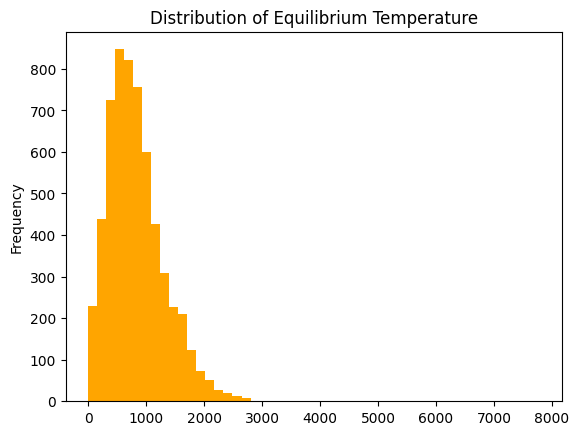

In [108]:
df_t["pl_eqt"].plot(kind="hist" , bins = 50 , title= "Distribution of Equilibrium Temperature", color='orange')

In [109]:
#calculating mean and median
eqt_mean = np.mean(df_t["pl_eqt"])
eqt_median = np.median(df_t["pl_eqt"])

print(f"For equlibrium temperature, mean: {eqt_mean:.1f} K and median: {eqt_median} K \n")

#finding hottest planet
print(df_t.nlargest(1, "pl_eqt")[["pl_name", "pl_eqt"]])

For equlibrium temperature, mean: 836.4 K and median: 758.0 K 

       pl_name   pl_eqt
2157  KOI-55 b  7777.78


'pl_eqt' is right skewed: the middle 50% percent of planets lie between about 500K and 1100K
(median=758K, mean=836.4K) , with the hottest planet being 'KOI-55 b' with a temperature of 7777.78K.


### 2b- Skewness of Orbital Period

<Axes: title={'center': 'Orbital Period'}, ylabel='Frequency'>

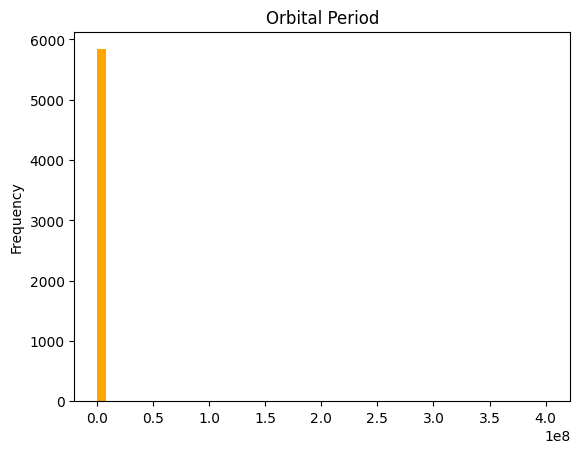

In [110]:
df_t["pl_orbper"].plot(kind="hist", bins=50, title="Orbital Period", color='orange')

The axis in this graph of raw data runs 4*10^8 days because of few extreme values, so every other planet is squeezed into one bin and the shape is invisible. The most extreme planet is COCONUTS-2b.

<Axes: title={'center': 'Orbital Period(log10)'}, ylabel='Frequency'>

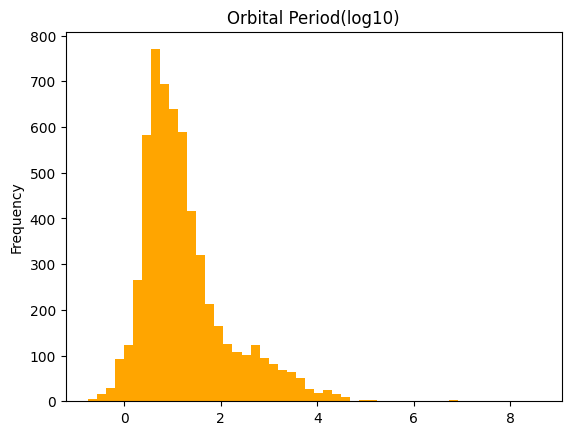

In [111]:
np.log10(df_t["pl_orbper"]).plot(kind ="hist" , bins =50 , title="Orbital Period(log10)", color='orange')

This graph shows the real shape as its ploted with log10 of orbital periods. It's right skewed as well.

Hence, we conclude that we can use log to show real distribution of data for data with skewed columns

###2c - Missing values in selected features

<Axes: title={'center': '% Missing Per Feature'}>

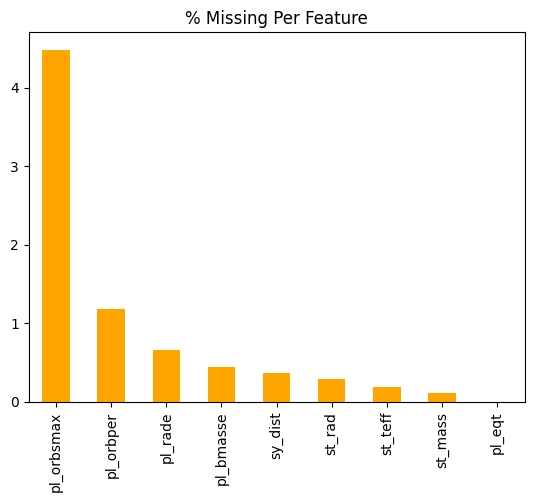

In [112]:
missing_t = (df_t[feats].isna().mean() *100).sort_values(ascending=False)
missing_t.plot(kind='bar', title ="% Missing Per Feature", color='orange')

In [113]:
print(df_t[feats].shape, df_t[feats].dropna().shape)

(5911, 9) (5493, 9)


###2d -Distance vs Equilibrium Temperature

<Axes: title={'center': 'Distancs v/s Temperature'}, xlabel='pl_orbsmax', ylabel='pl_eqt'>

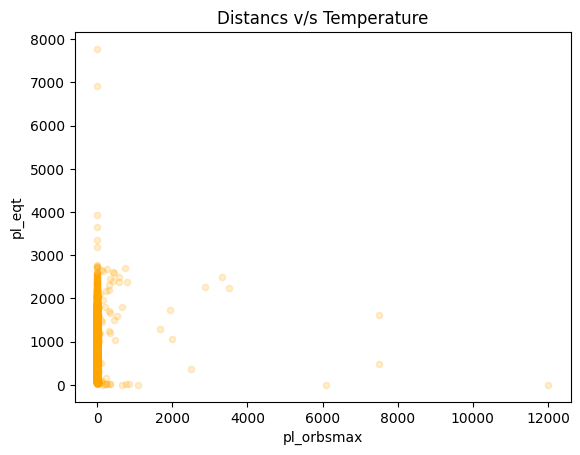

In [114]:
df_t.plot(kind="scatter", x= "pl_orbsmax", y= "pl_eqt", alpha = 0.2, title="Distancs v/s Temperature", color='orange')

This graph plots the raw data, and its stacked in a column, while a few lie beyond 1000au . Temperature spans 0-3000K mostly.

<Axes: title={'center': 'Log Dist v/s Log Temp'}, xlabel='log_dis', ylabel='log_temp'>

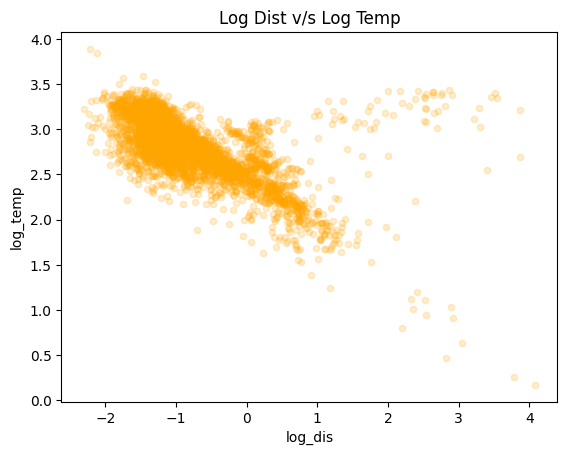

In [115]:
plot_df = pd.DataFrame({
    "log_dis": np.log10(df_t["pl_orbsmax"]),
    "log_temp": np.log10(df_t["pl_eqt"])})
plot_df.plot(kind="scatter", x="log_dis", y ="log_temp" ,alpha =0.2 , title="Log Dist v/s Log Temp", color='orange')

This is the graph with the log10 values plotted , and it the log10 values are more valuable , planets beyond 10au scatter awya from band, including some that are near 0K and some that are hot.

###2e - Stellar Temperature v/s Equilibrium Temperature

<Axes: title={'center': 'Stellar Temp v/s Equilibrium Temp'}, xlabel='st_teff', ylabel='pl_eqt'>

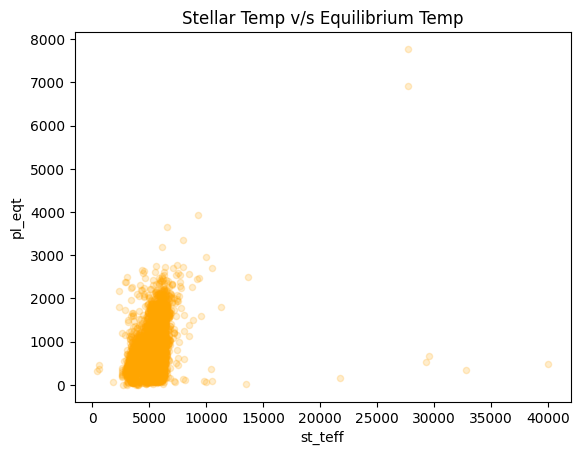

In [116]:
df_t.plot(kind ="scatter", x="st_teff", y ="pl_eqt", alpha = 0.2, title="Stellar Temp v/s Equilibrium Temp", color='orange')

Hotter stars have more hotter planets , but cloud is wide,stellar temperature of 5000K can have planet temperature from 0 to 2500K.

###2f - Correlation Heatmap

In [117]:
df_t[feats].corr().style.background_gradient(cmap="OrRd", vmin=-1, vmax=1).format("{:.2f}")

,pl_eqt,pl_rade,pl_bmasse,pl_orbper,pl_orbsmax,st_teff,st_rad,st_mass,sy_dist
pl_eqt,1.00,0.12,-0.03,-0.01,0.02,0.32,0.05,0.26,0.15
pl_rade,0.12,1.00,0.45,0.02,0.07,0.16,0.21,0.36,-0.23
pl_bmasse,-0.03,0.45,1.00,0.03,0.17,0.06,0.33,0.27,-0.17
pl_orbper,-0.01,0.02,0.03,1.00,1.00,-0.02,-0.00,-0.02,-0.01
pl_orbsmax,0.02,0.07,0.17,1.00,1.00,-0.02,-0.01,-0.03,-0.04
st_teff,0.32,0.16,0.06,-0.02,-0.02,1.00,-0.04,0.46,0.29
st_rad,0.05,0.21,0.33,-0.00,-0.01,-0.04,1.00,0.45,-0.03
st_mass,0.26,0.36,0.27,-0.02,-0.03,0.46,0.45,1.00,0.16
sy_dist,0.15,-0.23,-0.17,-0.01,-0.04,0.29,-0.03,0.16,1.00


In the heat map of raw data , the correlation between some features is close to none eventhough they are clearly related as per their log values (like pl_orbsmax and pl_eqt).

In [118]:
logged = df_t[feats].copy()
for c in ["pl_eqt", "pl_rade", "pl_bmasse", "pl_orbper", "pl_orbsmax", "st_teff", "st_rad", "st_mass", "sy_dist"]:
    logged[c] = np.log10(logged[c])

logged.corr().style.background_gradient(cmap="OrRd", vmin=-1, vmax=1).format("{:.2f}")

,pl_eqt,pl_rade,pl_bmasse,pl_orbper,pl_orbsmax,st_teff,st_rad,st_mass,sy_dist
pl_eqt,1.00,-0.14,-0.21,-0.79,-0.66,0.30,0.20,0.28,0.39
pl_rade,-0.14,1.00,0.92,0.41,0.45,0.18,0.42,0.32,-0.18
pl_bmasse,-0.21,0.92,1.00,0.49,0.54,0.14,0.43,0.29,-0.23
pl_orbper,-0.79,0.41,0.49,1.00,1.00,0.05,0.30,0.15,-0.26
pl_orbsmax,-0.66,0.45,0.54,1.00,1.00,0.07,0.31,0.15,-0.24
st_teff,0.30,0.18,0.14,0.05,0.07,1.00,0.43,0.78,0.46
st_rad,0.20,0.42,0.43,0.30,0.31,0.43,1.00,0.78,0.22
st_mass,0.28,0.32,0.29,0.15,0.15,0.78,0.78,1.00,0.39
sy_dist,0.39,-0.18,-0.23,-0.26,-0.24,0.46,0.22,0.39,1.00


After the values are turned into their log values, the relationship becomes more distinct and clear(like pl_orbper , pl_orbsmax, etc).

# 3 - Data Preprocessing

In [119]:
# physics: T_eq depends on stellar temperature, stellar radius and orbital distance
relevant_feats = ['pl_orbper', 'pl_orbsmax', 'st_teff', 'st_rad', 'st_mass', 'pl_bmasse']

In [120]:
# log10 correlation of every candidate with the target (evidence for the feature choice)
logged.corr()["pl_eqt"].drop("pl_eqt").round(2).sort_values()

,pl_eqt
pl_orbper,-0.79
pl_orbsmax,-0.66
pl_bmasse,-0.21
pl_rade,-0.14
st_rad,0.20
st_mass,0.28
st_teff,0.30
sy_dist,0.39


These features are chosen because they follow the physics of equilibrium temperature(stellar temp , stellar radius , orbital distance) plus the log10 correlations shown above. A correlation threshold alonse is not a reliable filter , as 'st_rad' has low log10 correlaton of 0.20 but with 'pl_eqt' it improves the model once the other features are present. sy_dist is excluded because their distance from earth is not useful for the target.

In [121]:
target = "pl_eqt"

def make_X(data, feat_cols):
    """Select the feature columns and take log10; non-positive values become NaN."""
    X = data[feat_cols].copy()
    for c in feat_cols:
        X[c] = np.log10(X[c].where(X[c] > 0))
    return X

In [122]:
seed = np.random.default_rng(42)
perm = seed.permutation(len(df_t))
n_test = int(round(0.2 * len(df_t)))

test_df  = df_t.iloc[perm[:n_test]].reset_index(drop=True)
train_df = df_t.iloc[perm[n_test:]].reset_index(drop=True)
print(len(train_df), "train rows,", len(test_df), "test rows")

4729 train rows, 1182 test rows


In [123]:
X_train = make_X(train_df, relevant_feats)

fill_values = X_train.median()
X_train = X_train.fillna(fill_values)
mu = X_train.mean()
sd = X_train.std(ddof=0)

def preprocess(data):
    X = make_X(data, relevant_feats).fillna(fill_values)
    return (X - mu) / sd

def add_intercept(Z):
    return np.c_[np.ones(len(Z)), Z.values]

Z_train = preprocess(train_df)
Z_test  = preprocess(test_df)
A_train = add_intercept(Z_train)
A_test  = add_intercept(Z_test)

y_train_log = np.log10(train_df[target].values)
y_train = train_df[target].values
y_test  = test_df[target].values

print("A_train", A_train.shape, "| A_test", A_test.shape)
print("train feature means ~0:", Z_train.mean().round(3).to_dict())
print("train feature stds  ~1:", Z_train.std(ddof=0).round(3).to_dict())
print("test  feature means (not exactly 0):", Z_test.mean().round(3).to_dict())

A_train (4729, 7) | A_test (1182, 7)
train feature means ~0: {'pl_orbper': 0.0, 'pl_orbsmax': -0.0, 'st_teff': -0.0, 'st_rad': 0.0, 'st_mass': 0.0, 'pl_bmasse': -0.0}
train feature stds  ~1: {'pl_orbper': 1.0, 'pl_orbsmax': 1.0, 'st_teff': 1.0, 'st_rad': 1.0, 'st_mass': 1.0, 'pl_bmasse': 1.0}
test  feature means (not exactly 0): {'pl_orbper': 0.022, 'pl_orbsmax': 0.019, 'st_teff': -0.002, 'st_rad': 0.036, 'st_mass': 0.015, 'pl_bmasse': 0.045}


#4 - Linear Regression

In [124]:
def fit_normal_equation(X, y):
    return np.linalg.solve(X.T @ X, X.T @ y)

def predict(X, w):
    return X @ w

w = fit_normal_equation(A_train, y_train_log)
weights = pd.Series(w, index=["intercept"] + relevant_feats)
print(weights.round(4))

pred_test_log = predict(A_test, w)
pred_test = 10 ** pred_test_log

def predict_temperature(new_df):
    return 10 ** predict(add_intercept(preprocess(new_df)), w)

intercept     2.8358
pl_orbper    -0.2106
pl_orbsmax   -0.0780
st_teff       0.0907
st_rad        0.1493
st_mass      -0.0662
pl_bmasse     0.0194
dtype: float64


In [125]:
exponents = pd.Series(w[1:] / sd.values, index=relevant_feats)

orbital_exp = exponents["pl_orbper"] + (2/3) * exponents["pl_orbsmax"]

compare = pd.DataFrame({
    "fitted exponent": [exponents["st_teff"], exponents["st_rad"], orbital_exp],
    "simple physics":  [1.0, 0.5, -1/3]},
    index=["st_teff", "st_rad", "orbital period (P and a combined)"])
compare.round(2)

,fitted exponent,simple physics
st_teff,1.04,1.00
st_rad,0.54,0.50
orbital period (P and a combined),-0.31,-0.33


# 5 - Evaluation

In [126]:
def mae(y, p):
    return np.mean(np.abs(y - p))

def rmse(y, p):
    return np.sqrt(np.mean((y - p) ** 2))

def r2_score_np(y, p):
    ss_res = np.sum((y - p) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return 1 - ss_res / ss_tot

In [127]:
test_mae  = mae(y_test, pred_test)
test_rmse = rmse(y_test, pred_test)
test_r2   = r2_score_np(y_test, pred_test)
print(f"MAE  = {test_mae:.2f} K")
print(f"RMSE = {test_rmse:.2f} K")
print(f"R2   = {test_r2:.2f}")

MAE  = 83.51 K
RMSE = 209.04 K
R2   = 0.82


In [128]:
base = np.full_like(y_test, y_train.mean(), dtype=float)
print(f"Baseline (always predict the mean): MAE = {mae(y_test, base):.1f} K, RMSE = {rmse(y_test, base):.1f} K")

Baseline (always predict the mean): MAE = 383.3 K, RMSE = 493.7 K


<Axes: title={'center': 'Actual vs predicted equilibrium temperature (test set)'}, xlabel='actual', ylabel='predicted'>

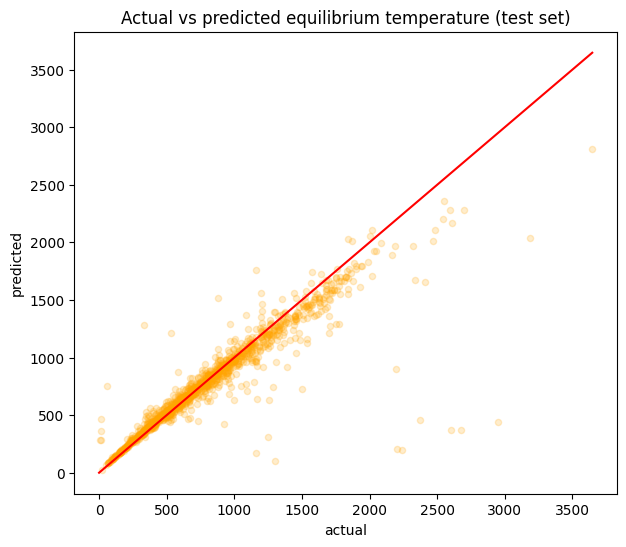

In [129]:
results = pd.DataFrame({"pl_name": test_df["pl_name"],
                        "actual": y_test,
                        "predicted": pred_test})

ax = results.plot(kind="scatter", x="actual", y="predicted", alpha=0.2, figsize=(7, 6),
                  title="Actual vs predicted equilibrium temperature (test set)", color ="orange")

lim = [0, max(results["actual"].max(), results["predicted"].max())]
pd.DataFrame({"actual": lim, "predicted": lim}).plot(x="actual", y="predicted", ax=ax, color="red", legend=False)

within 100 K: 0.808 | within 200 K: 0.931


,pl_name,actual,predicted,error,abs_error,discoverymethod
0,ZTF J1230-2655 b,2949.65,439.328683,-2510.321317,2510.321317,Transit
1,2MASS J11011926-7732383 b,2677.00,374.403645,-2302.596355,2302.596355,Imaging
2,CT Cha b,2600.00,373.360012,-2226.639988,2226.639988,Imaging
3,USco1556 b,2240.00,198.755904,-2041.244096,2041.244096,Imaging
4,DH Tau b,2200.00,203.886168,-1996.113832,1996.113832,Imaging


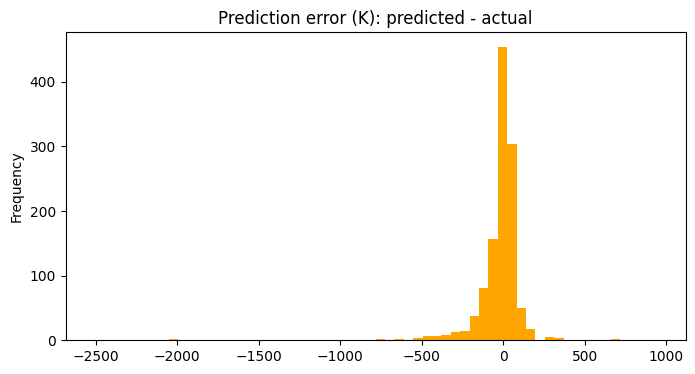

In [130]:
results["error"] = results["predicted"] - results["actual"]
results["error"].plot(kind="hist", bins=60, title="Prediction error (K): predicted - actual", figsize=(8, 4), color ="orange")
print("within 100 K:", round((results["error"].abs() < 100).mean(), 3),
      "| within 200 K:", round((results["error"].abs() < 200).mean(), 3))

results["abs_error"] = results["error"].abs()
results.nlargest(5, "abs_error").merge(test_df[["pl_name", "discoverymethod"]], on="pl_name")

#6 - Final Prediction

In [131]:
hottest  = results.loc[results["predicted"].idxmax()]
coldest  = results.loc[results["predicted"].idxmin()]
print("Hottest planet by prediction:", hottest["pl_name"],
      f"| predicted {hottest['predicted']:.0f} K, actual {hottest['actual']:.0f} K")
print("Coldest planet by prediction:", coldest["pl_name"],
      f"| predicted {coldest['predicted']:.0f} K, actual {coldest['actual']:.0f} K")
print()
print(results.nlargest(5, "predicted")[["pl_name", "predicted", "actual"]].round(0))
print()
print(results.nsmallest(5, "predicted")[["pl_name", "predicted", "actual"]].round(0))

Hottest planet by prediction: TOI-2109 b | predicted 2813 K, actual 3646 K
Coldest planet by prediction: DP Leo b | predicted 28 K, actual 24 K

            pl_name  predicted  actual
1134     TOI-2109 b     2813.0  3646.0
693        KOI-13 b     2362.0  2550.0
556   Kepler-1171 b     2283.0  2700.0
324     MASCARA-1 b     2282.0  2594.0
80       TOI-1518 b     2200.0  2546.0

         pl_name  predicted  actual
312     DP Leo b       28.0    24.0
17   HIP 35965 b       63.0    49.0
676  HD 168863 b       80.0    63.0
899   HD 73267 c       86.0    70.0
524   HD 16905 b       87.0    70.0


#7 - Gradient Descent(Bonus)

max |w_gd - w_normal_equation| = 1.0547118733938987e-15


<Axes: title={'center': 'Gradient descent: training MSE (log10 K) every 20 steps'}>

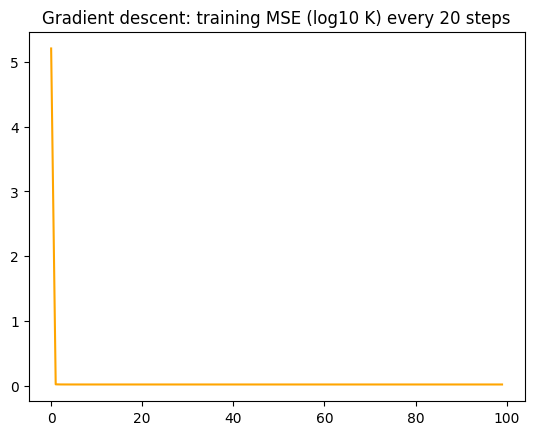

In [132]:
def grad_des(X,y,lr=0.1, n_iter=2000):
  n=len(y)
  w= np.zeros(X.shape[1])
  losses =[]
  for i in range(n_iter):
    grad =(2/n)*X.T @(X@w -y)
    w -= lr*grad
    if i % 20 == 0:
            losses.append(np.mean((X @ w - y) ** 2))
  return w, losses

w_gd, losses = grad_des(A_train, y_train_log)
print("max |w_gd - w_normal_equation| =", np.abs(w_gd - w).max())
pd.Series(losses).plot(title="Gradient descent: training MSE (log10 K) every 20 steps",color= "orange")